In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
#Download data
tickers = ["MSFT", "AAPL", "GOOGL"]

start_date = "2024-05-23"
end_date = "2026-05-23"  # yfinance end date is exclusive

raw_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

# Extract unadjusted daily closing prices
prices = raw_data["Close"][tickers].copy()

prices = prices.dropna()

print("First five observations:")
display(prices.head())

print("Last five observations:")
display(prices.tail())

print("Total number of observations:", len(prices))


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


First five observations:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2024-05-23,427.000000,186.880005,173.550003
2024-05-24,430.160004,189.979996,174.990005
2024-05-28,430.320007,189.990005,176.399994
2024-05-29,429.170013,190.289993,175.899994
2024-05-30,414.670013,191.289993,172.110001


Last five observations:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2026-05-18,423.540009,297.839996,396.940002
2026-05-19,417.420013,298.970001,387.660004
2026-05-20,421.059998,302.250000,388.910004
2026-05-21,419.089996,304.989990,387.660004
2026-05-22,418.570007,308.820007,382.970001


Total number of observations: 501


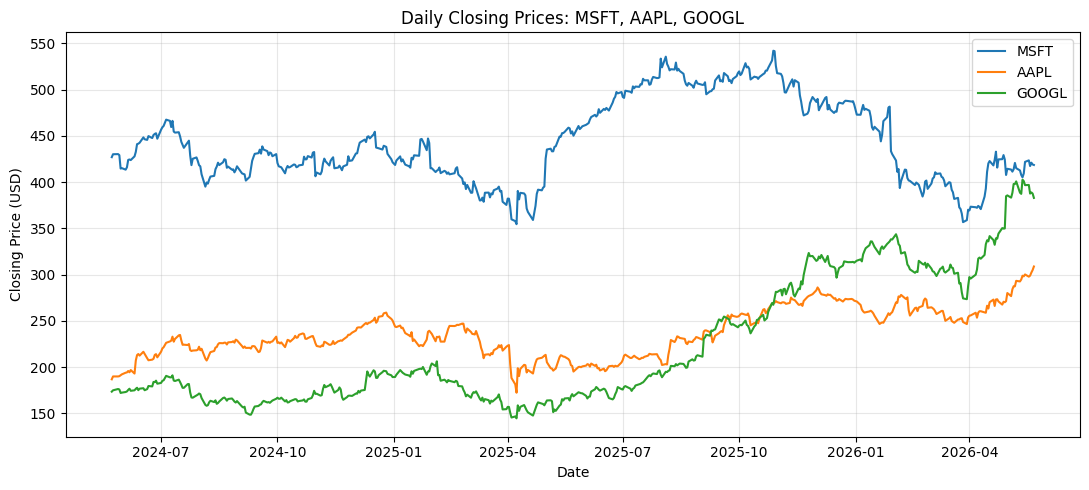

In [3]:
#Plot historical prices
plt.figure(figsize=(11, 5))

for ticker in tickers:
    plt.plot(prices.index, prices[ticker], label=ticker)

plt.title("Daily Closing Prices: MSFT, AAPL, GOOGL")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
#Calculate daily log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

print("First five daily log returns:")
display(log_returns.head())

print("Last five daily log returns:")
display(log_returns.tail())

print("Total number of return observations:", len(log_returns))

First five daily log returns:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2024-05-24,0.007373,0.016452,0.008263
2024-05-28,0.000372,0.000053,0.008025
2024-05-29,-0.002676,0.001578,-0.002838
2024-05-30,-0.034370,0.005241,-0.021782
2024-05-31,0.001109,0.005006,0.002263


Last five daily log returns:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2026-05-18,0.003832,-0.007992,0.000403
2026-05-19,-0.014555,0.003787,-0.023656
2026-05-20,0.008682,0.010911,0.003219
2026-05-21,-0.004690,0.009024,-0.003219
2026-05-22,-0.001242,0.012480,-0.012172


Total number of return observations: 500


In [17]:
#Portfolio weights
market_caps = pd.Series(
    [3.109, 4.536, 4.640],
    index=tickers
)

V0 = 1_000_000

weights = market_caps / market_caps.sum()

portfolio_values = weights * V0

weight_table = pd.DataFrame({
    "Market Cap (Trillion USD)": market_caps,
    "Portfolio Weight": weights,
    "Portfolio Investment ($)": portfolio_values
})

display(weight_table)

print("Sum of portfolio weights:", weights.sum())


,Market Cap (Trillion USD),Portfolio Weight,Portfolio Investment ($)
MSFT,3.109,0.253073,253072.853073
AAPL,4.536,0.369231,369230.769231
GOOGL,4.640,0.377696,377696.377696


Sum of portfolio weights: 0.9999999999999999


In [6]:
#Define the three loss functions
w = weights.loc[tickers].to_numpy()

def calculate_losses(X, w, V0):
    X = np.asarray(X)

    full = V0 * (1 - np.exp(X) @ w)

    linear = -V0 * (X @ w)

    quadratic = -V0 * ((X + 0.5 * X**2) @ w)

    return full, linear, quadratic

historical_X = log_returns[tickers].to_numpy()

L_full, L_lin, L_quad = calculate_losses(
    historical_X, w, V0
)


In [7]:
#Empirical VaR results
confidence = 0.95

empirical_var = pd.Series({
    "Full": np.quantile(L_full, confidence),
    "Linear": np.quantile(L_lin, confidence),
    "Quadratic": np.quantile(L_quad, confidence)
}, name="Empirical 95% VaR ($)")

display(empirical_var.to_frame())


,Empirical 95% VaR ($)
Full,21045.338698
Linear,21418.353814
Quadratic,21040.898072


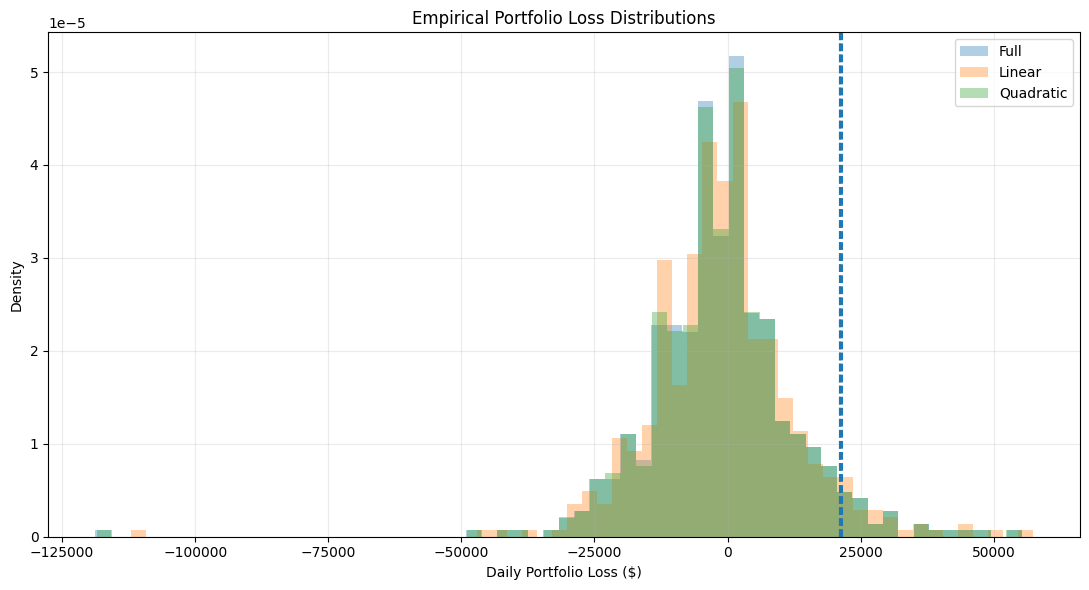

In [8]:
#Visualize the historical loss distributions
plt.figure(figsize=(11, 6))

for name, losses in {
    "Full": L_full,
    "Linear": L_lin,
    "Quadratic": L_quad
}.items():
    plt.hist(
        losses, bins=60, density=True,
        alpha=0.35, label=name
    )
    plt.axvline(
        np.quantile(losses, 0.95),
        linestyle="--", linewidth=1.5
    )

plt.title("Empirical Portfolio Loss Distributions")
plt.xlabel("Daily Portfolio Loss ($)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [9]:
#Implement EWMA recursively
lambda_ewma = 0.97
theta_ewma = 0.97

X = log_returns[tickers].to_numpy()
n_assets = len(tickers)

# Initial values
mu = np.zeros(n_assets)
Sigma = np.zeros((n_assets, n_assets))

# Save estimates for optional visualization
mu_history = []
cov_history = []

for x_t in X:
    mu_old = mu.copy()

    # Covariance uses the mean before updating it
    deviation = x_t - mu_old

    Sigma = (
        theta_ewma * Sigma
        + (1 - theta_ewma) * np.outer(deviation, deviation)
    )

    mu = (
        lambda_ewma * mu_old
        + (1 - lambda_ewma) * x_t
    )

    mu_history.append(mu.copy())
    cov_history.append(Sigma.copy())

mu_ewma = pd.Series(mu, index=tickers)

Sigma_ewma = pd.DataFrame(
    Sigma, index=tickers, columns=tickers
)

print("EWMA mean vector:")
display(mu_ewma.to_frame("Daily Mean"))

print("EWMA covariance matrix:")
display(Sigma_ewma)


EWMA mean vector:


,Daily Mean
MSFT,0.000473
AAPL,0.003636
GOOGL,0.003306


EWMA covariance matrix:


,MSFT,AAPL,GOOGL
MSFT,0.000314,0.000034,0.000003
AAPL,0.000034,0.000193,0.000081
GOOGL,0.000003,0.000081,0.000459


In [10]:
#Compute annualized volatility estimates
ewma_daily_vol = np.sqrt(np.diag(Sigma))

ewma_annual_vol = ewma_daily_vol * np.sqrt(252)

vol_table = pd.DataFrame({
    "Daily Volatility": ewma_daily_vol,
    "Annualized Volatility": ewma_annual_vol
}, index=tickers)

display(vol_table)


,Daily Volatility,Annualized Volatility
MSFT,0.017728,0.281416
AAPL,0.013881,0.220355
GOOGL,0.021433,0.340241


In [11]:
#Analytical linear VaR
mu_vec = mu_ewma.loc[tickers].to_numpy()
cov_mat = Sigma_ewma.loc[tickers, tickers].to_numpy()

# Mean and standard deviation of linear loss
mean_loss = -V0 * (w @ mu_vec)

std_loss = V0 * np.sqrt(w @ cov_mat @ w)

z_95 = norm.ppf(0.95)

var_linear_analytical = mean_loss + z_95 * std_loss

print(f"Mean linear loss: ${mean_loss:,.2f}")
print(f"Standard deviation: ${std_loss:,.2f}")
print(f"95% Normal quantile: {z_95:.5f}")
print(f"Analytical Linear VaR: ${var_linear_analytical:,.2f}")


Mean linear loss: $-2,710.92
Standard deviation: $11,903.81
95% Normal quantile: 1.64485
Analytical Linear VaR: $16,869.11


In [12]:
#Monte Carlo simulation
N = 100_000

rng = np.random.default_rng(42)

simulated_X = rng.multivariate_normal(
    mean=mu_vec,
    cov=cov_mat,
    size=N
)

MC_full, MC_lin, MC_quad = calculate_losses(
    simulated_X, w, V0
)

var_full_MC = np.quantile(MC_full, 0.95)
var_quad_MC = np.quantile(MC_quad, 0.95)

normal_var = pd.Series({
    "Full": var_full_MC,
    "Linear": var_linear_analytical,
    "Quadratic": var_quad_MC
}, name="Normal Model 95% VaR ($)")

display(normal_var.to_frame())


,Normal Model 95% VaR ($)
Full,16664.947725
Linear,16869.110890
Quadratic,16662.275502


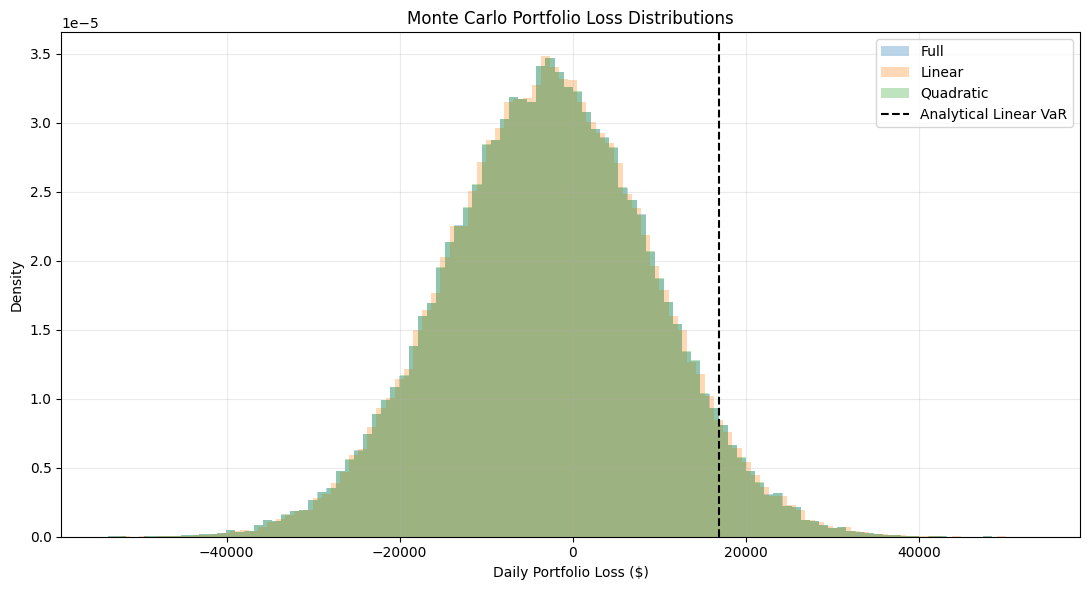

In [13]:
#Visualize Monte Carlo loss distributions
plt.figure(figsize=(11, 6))

for name, losses in {
    "Full": MC_full,
    "Linear": MC_lin,
    "Quadratic": MC_quad
}.items():

    plt.hist(
        losses,
        bins=100,
        density=True,
        alpha=0.30,
        label=name
    )

plt.axvline(
    var_linear_analytical,
    color="black",
    linestyle="--",
    label="Analytical Linear VaR"
)

plt.title("Monte Carlo Portfolio Loss Distributions")
plt.xlabel("Daily Portfolio Loss ($)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [14]:
#Optional simulation validation
var_linear_MC = np.quantile(MC_lin, 0.95)

print(f"Analytical Linear VaR: ${var_linear_analytical:,.2f}")
print(f"Monte Carlo Linear VaR: ${var_linear_MC:,.2f}")
print(f"Difference: ${var_linear_MC - var_linear_analytical:,.2f}")


Analytical Linear VaR: $16,869.11
Monte Carlo Linear VaR: $16,914.80
Difference: $45.69


In [15]:
#Final comparison table
comparison = pd.DataFrame({
    "Empirical VaR ($)": empirical_var,
    "Normal EWMA VaR ($)": normal_var
})

comparison["Difference ($)"] = (
    comparison["Normal EWMA VaR ($)"]
    - comparison["Empirical VaR ($)"]
)

comparison["Difference (%)"] = (
    comparison["Difference ($)"]
    / comparison["Empirical VaR ($)"]
    * 100
)

display(comparison.round(2))


,Empirical VaR ($),Normal EWMA VaR ($),Difference ($),Difference (%)
Full,21045.34,16664.95,-4380.39,-20.81
Linear,21418.35,16869.11,-4549.24,-21.24
Quadratic,21040.90,16662.28,-4378.62,-20.81


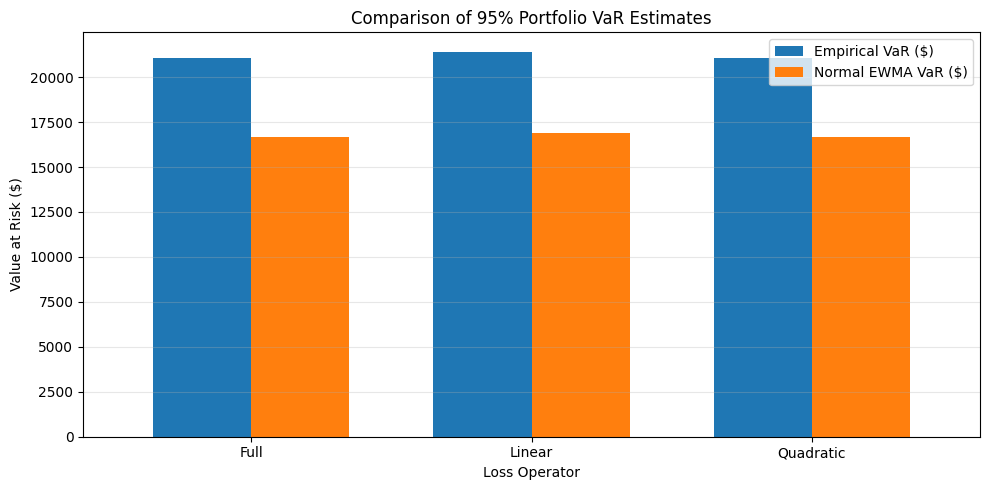

In [16]:
#Comparison bar chart
ax = comparison[
    ["Empirical VaR ($)", "Normal EWMA VaR ($)"]
].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

ax.set_title("Comparison of 95% Portfolio VaR Estimates")
ax.set_xlabel("Loss Operator")
ax.set_ylabel("Value at Risk ($)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [18]:
#Automatic interpretation of results
print("FINAL VaR COMPARISON")
print("=" * 50)

display(comparison.round(2))

for method in ["Empirical VaR ($)", "Normal EWMA VaR ($)"]:
    vals = comparison[method]
    spread_pct = 100 * (vals.max() - vals.min()) / vals["Full"]

    print(f"\n{method}")
    print(f"Highest estimate: {vals.idxmax()}")
    print(f"Lowest estimate: {vals.idxmin()}")
    print(f"Range relative to full VaR: {spread_pct:.2f}%")

print("\nEmpirical versus Normal EWMA differences:")
for operator in comparison.index:
    diff = comparison.loc[operator, "Difference (%)"]
    print(f"{operator}: {diff:+.2f}%")


FINAL VaR COMPARISON


,Empirical VaR ($),Normal EWMA VaR ($),Difference ($),Difference (%)
Full,21045.34,16664.95,-4380.39,-20.81
Linear,21418.35,16869.11,-4549.24,-21.24
Quadratic,21040.90,16662.28,-4378.62,-20.81



Empirical VaR ($)
Highest estimate: Linear
Lowest estimate: Quadratic
Range relative to full VaR: 1.79%

Normal EWMA VaR ($)
Highest estimate: Linear
Lowest estimate: Quadratic
Range relative to full VaR: 1.24%

Empirical versus Normal EWMA differences:
Full: -20.81%
Linear: -21.24%
Quadratic: -20.81%



## Part 6: Comparison of VaR Estimates

The empirical and Normal EWMA approaches produce materially different 95% VaR estimates for the USD 1,000,000 market-capitalization-weighted portfolio.

Under the empirical approach, the full, linear, and quadratic VaR estimates are USD 21,045.34, USD 21,418.35, and USD 21,040.90, respectively. Under the Normal EWMA approach, the corresponding estimates are USD 16,664.95, USD 16,869.11, and USD 16,662.28.

### Comparison of Loss Operators

Within each approach, the three loss operators produce relatively similar VaR estimates. The linear approximation generates the highest VaR, while the full and quadratic loss operators yield almost identical results.

For the empirical approach, the quadratic VaR differs from the full VaR by only USD 4.44, whereas the linear VaR is USD 373.01 higher than the full VaR.

This suggests that the quadratic approximation captures the nonlinear effects of the portfolio loss function very accurately over the observed daily return range. The linear approximation produces a slightly more conservative estimate because it ignores the second-order terms in the exponential loss function.

### Comparison of Estimation Methods

The Normal EWMA approach produces VaR estimates approximately 20.8%–21.2% lower than the empirical approach, representing a material difference.

For example, the empirical full VaR is USD 21,045.34, while the Normal EWMA full VaR is USD 16,664.95, a difference of approximately USD 4,380.39, or 20.81%.

This discrepancy may arise from several factors.

First, the empirical method directly incorporates the historical return distribution, including potentially heavy tails, skewness, and extreme observations. In contrast, the Normal EWMA method assumes that daily log returns follow a multivariate normal distribution.

Second, the EWMA method assigns greater weights to recent observations, potentially producing different mean and covariance estimates compared with the equally weighted historical distribution.

Furthermore, the EWMA estimates imply a positive expected portfolio return, corresponding to an expected linear loss of negative USD 2,710.92. This positive expected return reduces the analytical linear VaR under the normal assumption.

### Conclusion

The choice of estimation method has a substantially greater effect on the resulting VaR than the choice of loss operator.

The empirical approach estimates a potential one-day loss of approximately USD 21,045, or 2.10% of the portfolio value, while the Normal EWMA approach estimates approximately USD 16,665, or 1.67%, using the full loss operator.

The relatively small differences between the full and quadratic VaR estimates indicate that the second-order approximation is sufficiently accurate for this portfolio under the observed return scenarios.

Overall, the results demonstrate that VaR estimates are sensitive to distributional assumptions and parameter estimation methods. A lower VaR estimate does not necessarily indicate a more accurate risk model, emphasizing the importance of model validation and backtesting in portfolio risk management.
